# 03 · Modelos · «BiciPrevisión» · equipo «Las Palmeras» (entrega de referencia, Sprint 15)

**Pregunta de negocio:** *¿podemos prever cuántas bicis se alquilarán en cada hora de mañana?* Umbral de éxito (Sprint 14): **bajar un 25 % el MAE del baseline** en la validación de sep–oct 2012.

**Qué hace este cuaderno:** repite el *baseline* del Sprint 14, prueba **tres modelos clásicos y una red neuronal con la misma partición**, anota **cada prueba** en `registro.csv`, comprueba que **no hay fugas**, elige el candidato **solo con la validación**, lo evalúa en el test **una única vez**, lo guarda con sus metadatos y hace una primera explicación.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (unos 2–3 minutos). `SEMILLA = 42`. El registro se rehace entero en cada ejecución.

| Sección | Quién | Qué |
|---|---|---|
| Común (0–3) | Marta (responsable técnica) | Importaciones, semilla, registro, datos y partición |
| A | Marta | *Baselines* y boosting (sin y con clima) |
| B | Persona B | Red neuronal con 3 semillas y una validación barajada (código de la IA) |
| C | Persona C | Ajuste de hiperparámetros y pruebas de fuga y de clima con error |
| D | Persona D | Regresión lineal, bosque aleatorio y repetición de una prueba de Marta |

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


In [2]:
import sys, time, json, random, hashlib
from datetime import datetime
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance

def fijar_semillas(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    os.environ["PYTHONHASHSEED"] = str(semilla)
    return np.random.default_rng(semilla)

SEMILLA = 42
rng = fijar_semillas(SEMILLA)

ENTORNO = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
print(json.dumps(ENTORNO, indent=2))

{
  "python": "3.13.18",
  "numpy": "2.5.3",
  "pandas": "2.3.3",
  "scikit-learn": "1.9.1"
}


## 1. El registro de experimentos

In [3]:
RUTA_REGISTRO = "registro.csv"
COLUMNAS = ["id", "fecha", "responsable", "modelo", "hiperparametros", "datos_hash", "semilla",
            "metrica", "valor_cv", "desv_cv", "tiempo_s", "notas"]
if os.path.exists(RUTA_REGISTRO):
    os.remove(RUTA_REGISTRO)          # cada ejecución completa rehace el registro desde cero

FECHA_FIJA = None   # en el ejemplo de referencia se fija la fecha de cada sesión para que el registro salga igual; en vuestro cuaderno, dejadlo en None

def registrar(responsable, modelo, hiperparametros, datos_hash, semilla, metrica, valor_cv, desv_cv, tiempo_s, notas=""):
    existe = os.path.exists(RUTA_REGISTRO)
    n = len(pd.read_csv(RUTA_REGISTRO)) if existe else 0
    fila = pd.DataFrame([{
        "id": n + 1, "fecha": FECHA_FIJA or datetime.now().strftime("%Y-%m-%d %H:%M"), "responsable": responsable, "modelo": modelo,
        "hiperparametros": json.dumps(hiperparametros, sort_keys=True), "datos_hash": datos_hash, "semilla": semilla,
        "metrica": metrica, "valor_cv": round(float(valor_cv), 4), "desv_cv": round(float(desv_cv), 4),
        "tiempo_s": round(float(tiempo_s), 2), "notas": notas}], columns=COLUMNAS)
    fila.to_csv(RUTA_REGISTRO, mode="a", header=not existe, index=False)
    return n + 1

## 2. Datos y partición común (la del Sprint 14, más validación temporal)

In [4]:
horas = pd.read_csv(dato("bicis_horas.csv"), parse_dates=["dteday"])
horas["ts"] = horas["dteday"] + pd.to_timedelta(horas["hr"], unit="h")
indice = pd.date_range(horas["ts"].min(), horas["ts"].max(), freq="h")
serie = horas.set_index("ts").reindex(indice)           # una fila por hora, sin saltos
serie["hueco"] = serie["cnt"].isna()                    # horas que no están en el CSV (nadie alquiló)
serie["cnt"] = serie["cnt"].fillna(0)                   # decisión de limpieza: sin fila = 0 bicis alquiladas
for c in ["holiday", "workingday"]:
    serie[c] = serie.groupby(serie.index.normalize())[c].transform("max")   # el día es laborable o festivo en todas sus horas
for c in ["weathersit", "temp", "atemp", "hum", "windspeed"]:
    serie[c] = serie[c].ffill()                         # el clima de una hora sin fila se toma de la anterior
serie["hr"], serie["weekday"], serie["mnth"] = serie.index.hour, serie.index.dayofweek, serie.index.month

CLIMA = ["weathersit", "temp", "atemp", "hum", "windspeed"]

def construir_variables(s):
    """Variables para predecir cada hora de MAÑANA con lo que se sabe a las 23:00 de hoy (retrasos de 24 h o más)."""
    x = pd.DataFrame(index=s.index)
    x["hr"], x["weekday"], x["mnth"] = s["hr"], s["weekday"], s["mnth"]
    x["holiday"], x["workingday"] = s["holiday"], s["workingday"]
    x["lag_24"] = s["cnt"].shift(24)                                         # la misma hora de hoy
    x["lag_168"] = s["cnt"].shift(168)                                       # la misma hora de la semana anterior
    x["media4sem"] = sum(s["cnt"].shift(168 * k) for k in (1, 2, 3, 4)) / 4  # media de esa hora en las 4 semanas anteriores
    x["nivel_7d"] = s["cnt"].shift(24).rolling(168).mean()                   # nivel medio de los últimos 7 días
    for c in CLIMA:
        x[c] = s[c]                                                          # clima de esa hora (en producción, la previsión)
    return x

# Partición por fechas (decidida antes de ver ningún resultado): lo último es el examen
FIN_ENTRENAMIENTO, FIN_VALIDACION = "2012-09-01", "2012-11-01"
x = construir_variables(serie)
y = serie["cnt"]
ok = x.notna().all(axis=1)                                   # las primeras 4 semanas no tienen todos los retrasos
x, y = x[ok], y[ok]
m_ent = x.index < FIN_ENTRENAMIENTO
m_val = (x.index >= FIN_ENTRENAMIENTO) & (x.index < FIN_VALIDACION)
m_test = x.index >= FIN_VALIDACION
hora_punta = (x["workingday"] == 1) & x["hr"].isin([7, 8, 9, 17, 18, 19])

def mae(real, pred):
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pred))))

def wape(real, pred):
    return float(np.sum(np.abs(np.asarray(real) - np.asarray(pred))) / np.sum(real))

def informe_metricas(real, pred, mascara_punta):
    return {"MAE": mae(real, pred), "WAPE": wape(real, pred), "MAE hora punta": mae(real[mascara_punta], np.asarray(pred)[mascara_punta.to_numpy()])}

# Datos de desarrollo (entrenamiento + validación) y test reservado
m_dev = m_ent | m_val
X_dev, y_dev, hp_dev = x[m_dev], y[m_dev], hora_punta[m_dev]
X_test, y_test = x[m_test], y[m_test]                      # NO SE TOCA hasta el paso 5
assert X_dev.index.max() < X_test.index.min()

METRICA = "MAE (bicis/hora)"
COLS_TODAS = list(X_dev.columns)
COLS_SIN_CLIMA = [c for c in COLS_TODAS if c not in CLIMA]
assert not {"cnt", "casual", "registered"} & set(COLS_TODAS), "variables que solo se conocen después de la hora"

# Validación temporal: 5 bloques de 61 días; en cada uno se entrena con todo lo anterior. El último bloque es la validación de sep–oct.
CV = TimeSeriesSplit(n_splits=5, test_size=int(m_val.sum()))
DATOS_HASH = hashlib.md5(pd.util.hash_pandas_object(serie[["cnt"] + CLIMA], index=True).values.tobytes()).hexdigest()[:8]
print("Huella de los datos:", DATOS_HASH, "· desarrollo:", X_dev.shape, "· test (sin tocar):", X_test.shape)
for i, (ent, val) in enumerate(CV.split(X_dev), 1):
    print(f"Bloque {i}: entrena con {len(ent):>6} horas (hasta {X_dev.index[ent[-1]].date()}) · prueba {X_dev.index[val[0]].date()} → {X_dev.index[val[-1]].date()}")
assert X_dev.index[val[0]] == pd.Timestamp("2012-09-01") and X_dev.index[val[-1]] == pd.Timestamp("2012-10-31 23:00")
print("✔ El último bloque es la validación de sep–oct 2012 (la del umbral de éxito)")

Huella de los datos: 95d6bcad · desarrollo: (15408, 14) · test (sin tocar): (1464, 14)
Bloque 1: entrena con   8088 horas (hasta 2011-12-31) · prueba 2012-01-01 → 2012-03-01
Bloque 2: entrena con   9552 horas (hasta 2012-03-01) · prueba 2012-03-02 → 2012-05-01
Bloque 3: entrena con  11016 horas (hasta 2012-05-01) · prueba 2012-05-02 → 2012-07-01
Bloque 4: entrena con  12480 horas (hasta 2012-07-01) · prueba 2012-07-02 → 2012-08-31
Bloque 5: entrena con  13944 horas (hasta 2012-08-31) · prueba 2012-09-01 → 2012-10-31
✔ El último bloque es la validación de sep–oct 2012 (la del umbral de éxito)


## 3. La función `experimento` (todas las pruebas pasan por aquí)

In [5]:
CATEGORICAS = ["hr", "weekday", "mnth", "weathersit"]
MODELOS, RESULTADOS = {}, {}

class IgualQue(BaseEstimator, RegressorMixin):
    """Baseline: copia una columna (por ejemplo, la misma hora de la semana pasada)."""
    def __init__(self, columna="lag_168"):
        self.columna = columna
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return X[self.columna].to_numpy()

def con_preparacion(modelo, columnas):
    """Codifica las categorías y escala los números DENTRO del modelo, para que se aprenda solo con el entrenamiento de cada bloque."""
    cat = [c for c in CATEGORICAS if c in columnas]
    num = [c for c in columnas if c not in cat]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])
    return Pipeline([("prep", pre), ("modelo", modelo)])

rng_ruido = np.random.default_rng(SEMILLA)
def con_ruido_clima(X, frac):
    """Simula una previsión del clima con error: ruido del `frac` en temperatura, humedad y viento, y el tipo de tiempo mal en `frac` de las horas."""
    X = X.copy()
    for c in ["temp", "atemp", "hum", "windspeed"]:
        X[c] = (X[c] * (1 + rng_ruido.normal(0, frac, len(X)))).clip(0, 1)
    cambia = rng_ruido.random(len(X)) < frac
    X.loc[cambia, "weathersit"] = rng_ruido.integers(1, 4, int(cambia.sum()))
    return X

def experimento(nombre, modelo, hiperparametros, responsable, columnas=None, notas="", validacion=None, ruido_clima=0.0, X=None):
    """Valida el modelo con los 5 bloques temporales, escribe UNA fila en el registro y devuelve (media, desviación) del MAE."""
    cols = columnas or COLS_TODAS
    Xd = X_dev if X is None else X
    temporal = validacion is None
    t0 = time.time()
    bloques, punta = [], []
    for ent, val in (CV if temporal else validacion).split(Xd):
        m = clone(modelo).fit(Xd.iloc[ent][cols], y_dev.iloc[ent])
        Xv = Xd.iloc[val][cols]
        if ruido_clima > 0:
            Xv = con_ruido_clima(Xv, ruido_clima)
        p = np.asarray(m.predict(Xv))
        mascara = hp_dev.iloc[val].to_numpy()
        bloques.append(mae(y_dev.iloc[val], p))
        punta.append(mae(y_dev.iloc[val].to_numpy()[mascara], p[mascara]))
    media, desv = float(np.mean(bloques)), float(np.std(bloques, ddof=1))
    nota = ((f"val sep-oct {bloques[-1]:.1f}" if temporal else "") + (" · " if temporal and notas else "") + notas).strip()
    registrar(responsable, nombre, hiperparametros, DATOS_HASH, SEMILLA, METRICA, media, desv, time.time() - t0, nota)
    MODELOS[nombre] = (clone(modelo), cols)
    RESULTADOS[nombre] = {"bloques": bloques, "val": bloques[-1] if temporal else None, "punta_val": punta[-1] if temporal else None}
    return media, desv

def imprimir(nombre, media, desv):
    r = RESULTADOS[nombre]
    val = f" · validación sep–oct {r['val']:.1f}" if r["val"] is not None else ""
    print(f"{nombre}: MAE {media:.1f} ± {desv:.1f}{val}")

## A · Marta · baselines y boosting

In [6]:
FECHA_FIJA = "2026-12-01"
# Baselines (primera fila del registro): lo más simple, sin aprender nada
media, desv = experimento("Baseline_semana_pasada", IgualQue("lag_168"), {"columna": "lag_168"}, responsable="Marta", notas="baseline del Sprint 14, repetido")
imprimir("Baseline_semana_pasada", media, desv)
media, desv = experimento("Baseline_media_4_semanas", IgualQue("media4sem"), {"columna": "media4sem"}, responsable="Marta", notas="segundo baseline")
imprimir("Baseline_media_4_semanas", media, desv)

# Boosting de árboles SIN y CON clima (early_stopping=False: así no se reserva ningún trozo barajado del entrenamiento)
def boosting(**extra):
    return HistGradientBoostingRegressor(**{"max_iter": 300, "learning_rate": 0.05, "early_stopping": False, "random_state": SEMILLA, **extra})

media, desv = experimento("HGB_sin_clima", boosting(), {"max_iter": 300, "learning_rate": 0.05}, responsable="Marta",
                          columnas=COLS_SIN_CLIMA, notas="sin las 5 variables de clima")
imprimir("HGB_sin_clima", media, desv)
media, desv = experimento("HGB_con_clima", boosting(), {"max_iter": 300, "learning_rate": 0.05}, responsable="Marta")
imprimir("HGB_con_clima", media, desv)

Baseline_semana_pasada: MAE 59.2 ± 9.2 · validación sep–oct 69.5
Baseline_media_4_semanas: MAE 49.7 ± 8.2 · validación sep–oct 57.6


HGB_sin_clima: MAE 67.2 ± 19.8 · validación sep–oct 63.9


HGB_con_clima: MAE 40.8 ± 6.7 · validación sep–oct 42.7


## B · Persona B · red neuronal y una validación que no vale

In [7]:
FECHA_FIJA = "2026-12-02"
# Red neuronal (MLPRegressor de scikit-learn): dos capas de 64 y 32 neuronas, con 3 semillas para ver cuánto depende del azar
for semilla in (42, 43, 44):
    red = TransformedTargetRegressor(
        regressor=MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=False, random_state=semilla),
        transformer=StandardScaler())
    nombre = f"RedNeuronal_MLP_semilla{semilla}"
    media, desv = experimento(nombre, con_preparacion(red, COLS_TODAS), {"hidden_layer_sizes": [64, 32], "max_iter": 200, "semilla_red": semilla},
                              responsable="Persona B", notas="código generado con IA, revisado a mano; el objetivo se escala para que la red aprenda")
    imprimir(nombre, media, desv)

# El código que nos dio la IA para «validar» barajaba las filas (KFold con shuffle=True). Lo probamos para ver qué pasa:
media, desv = experimento("HGB_KFold_barajado", boosting(), {"max_iter": 300, "learning_rate": 0.05, "validacion": "KFold(5, shuffle=True)"},
                          responsable="Persona B", validacion=KFold(5, shuffle=True, random_state=SEMILLA),
                          notas="NO CANDIDATO · ALARMA: código generado con IA que baraja las horas; sale demasiado bien (ve el futuro de la misma semana)")
imprimir("HGB_KFold_barajado", media, desv)

RedNeuronal_MLP_semilla42: MAE 67.2 ± 20.4 · validación sep–oct 57.3


RedNeuronal_MLP_semilla43: MAE 70.4 ± 14.7 · validación sep–oct 70.2


RedNeuronal_MLP_semilla44: MAE 66.9 ± 14.1 · validación sep–oct 74.3


HGB_KFold_barajado: MAE 26.7 ± 0.9


## C · Persona C · ajuste, fuga y clima con error

In [8]:
FECHA_FIJA = "2026-12-02"
# Ajuste de hiperparámetros del boosting, solo con la validación (cada valor es una fila)
for d in (3, 6):
    nombre = f"HGB_prof{d}"
    media, desv = experimento(nombre, boosting(max_depth=d), {"max_iter": 300, "learning_rate": 0.05, "max_depth": d}, responsable="Persona C", notas="ajuste de profundidad")
    imprimir(nombre, media, desv)
for it in (150, 600):
    nombre = f"HGB_iter{it}"
    media, desv = experimento(nombre, boosting(max_iter=it), {"max_iter": it, "learning_rate": 0.05}, responsable="Persona C", notas="ajuste de número de árboles")
    imprimir(nombre, media, desv)

# Prueba de fuga a propósito: `registered` (alquileres de socios) solo se conoce DESPUÉS de la hora
X_fuga = X_dev.copy()
X_fuga["registered"] = serie.loc[X_dev.index, "registered"].fillna(0)
media, desv = experimento("HGB_ConFuga", boosting(), {"max_iter": 300, "learning_rate": 0.05, "extra": "registered"}, responsable="Persona C",
                          columnas=COLS_TODAS + ["registered"], X=X_fuga,
                          notas="NO CANDIDATO · ALARMA: MAE sospechosamente bajo (fuga: registered se conoce después de la hora)")
imprimir("HGB_ConFuga", media, desv)

FECHA_FIJA = "2026-12-03"
# Riesgo R-01: en producción el clima será una previsión con error. El mejor modelo hasta ahora (profundidad 6), evaluado con un 10 % de error en el clima
media, desv = experimento("HGB_clima_con_error", boosting(max_depth=6), {"max_iter": 300, "learning_rate": 0.05, "max_depth": 6, "ruido_clima": 0.10}, responsable="Persona C",
                          ruido_clima=0.10, notas="NO CANDIDATO · el modelo de profundidad 6 con un 10 % de error en el clima: mide el riesgo R-01 (H13)")
imprimir("HGB_clima_con_error", media, desv)

HGB_prof3: MAE 43.3 ± 6.4 · validación sep–oct 45.6


HGB_prof6: MAE 40.6 ± 6.8 · validación sep–oct 42.2


HGB_iter150: MAE 41.2 ± 6.7 · validación sep–oct 44.2


HGB_iter600: MAE 40.9 ± 7.0 · validación sep–oct 42.3


HGB_ConFuga: MAE 17.0 ± 5.9 · validación sep–oct 15.9


HGB_clima_con_error: MAE 43.4 ± 7.5 · validación sep–oct 46.0


## D · Persona D · regresión lineal, bosque y repetición

In [9]:
FECHA_FIJA = "2026-12-02"
media, desv = experimento("Ridge", con_preparacion(Ridge(alpha=1.0), COLS_TODAS), {"alpha": 1.0}, responsable="Persona D", notas="regresión lineal con regularización; hr, día y mes como categorías")
imprimir("Ridge", media, desv)
media, desv = experimento("RandomForest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEMILLA, n_jobs=2),
                          {"n_estimators": 200, "min_samples_leaf": 5}, responsable="Persona D")
imprimir("RandomForest", media, desv)
media, desv = experimento("RandomForest_hoja20", RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=SEMILLA, n_jobs=2),
                          {"n_estimators": 200, "min_samples_leaf": 20}, responsable="Persona D", notas="ajuste: hojas más grandes")
imprimir("RandomForest_hoja20", media, desv)

FECHA_FIJA = "2026-12-03"
# Repetir una prueba de Marta sin cambiar nada, para comprobar que sale igual (si no, hay azar sin semilla)
media, desv = experimento("HGB_con_clima", boosting(), {"max_iter": 300, "learning_rate": 0.05}, responsable="Persona D", notas="repetición de la prueba de Marta: sale igual")
print(f"Repetición: MAE {media:.1f} ± {desv:.1f}")

Ridge: MAE 49.7 ± 6.4 · validación sep–oct 53.9


RandomForest: MAE 43.0 ± 7.6 · validación sep–oct 48.3


RandomForest_hoja20: MAE 44.3 ± 7.3 · validación sep–oct 50.5


Repetición: MAE 40.8 ± 6.7


## Comprobación de fugas (Persona C y D, antes de elegir)

1. **¿Las variables se conocerían en el momento de decidir?** Sí: el calendario y los retrasos de 24 h o más se conocen a las 23:00 de hoy. Quitamos `cnt`, `casual` y `registered` de la propia hora. **Pero** el clima del histórico es el clima *real*; en producción será una previsión (riesgo R-01): lo medimos con `HGB_clima_con_error`.
2. **¿El escalado y la codificación se aprenden solo con el entrenamiento?** Sí: `con_preparacion` los pone dentro del modelo y se aprenden en cada bloque. Los árboles no necesitan preparación. `early_stopping=False` evita que el boosting reserve un trozo barajado del entrenamiento.
3. **¿La partición respeta el tiempo?** Sí: `TimeSeriesSplit`, el entrenamiento es siempre anterior a la prueba. La validación barajada que propuso la IA (`HGB_KFold_barajado`) sale demasiado bien y queda **descartada**.
4. **¿Se ha ajustado algo mirando el test?** No: el test está apartado y hay una aserción de fechas; no se calcula nada con él hasta el paso 5.
5. **¿La métrica es demasiado buena para ser verdad?** Sí, **dos veces y a propósito**: `HGB_ConFuga` (usa `registered`) y `HGB_KFold_barajado`. Los dos llevan «NO CANDIDATO» en las notas y no entran en la elección. Ninguno de los modelos legítimos tiene un resultado así.

## Tutoría (02/12/2026)
- **Pregunta del docente:** «¿Qué comparación estáis haciendo y qué fuga podría haber?» → Comparamos modelos con los mismos 5 bloques temporales; la fuga más probable era el clima real y `registered`.
- **Consejo:** «Añadid una prueba con el clima con error: en producción solo tendréis una previsión.» → Hecho (`HGB_clima_con_error`).
- **Consejo:** «Con series, comparad por bloques, no solo la media: cada bloque tiene un nivel de demanda distinto.» → Lo usamos en la elección.

## 4. Limpiar el registro y comprobar las fugas con números

In [10]:
registro = pd.read_csv(RUTA_REGISTRO)
print(len(registro), "filas")
print(registro["responsable"].value_counts().to_string())
print("Casillas vacías por columna (solo `notas` puede tener):")
print(registro.isna().sum()[lambda s: s > 0].to_string() or "ninguna")
print("Repetidas (mismo modelo y ajustes):", int(registro.duplicated(subset=["modelo", "hiperparametros"]).sum()), "· la repetición de Persona D lleva una nota que lo dice")
print("Fila 1 del registro:", registro.loc[0, "modelo"])
print("Evidencia de las pruebas de fuga:")
for n in ("HGB_con_clima", "HGB_ConFuga", "HGB_KFold_barajado", "HGB_clima_con_error"):
    f = registro[registro["modelo"] == n].iloc[0]
    print(f"  {n:<22} MAE {f['valor_cv']:.1f} ± {f['desv_cv']:.1f}")

18 filas
responsable
Persona C    6
Marta        4
Persona B    4
Persona D    4
Casillas vacías por columna (solo `notas` puede tener):
Series([], )
Repetidas (mismo modelo y ajustes): 1 · la repetición de Persona D lleva una nota que lo dice
Fila 1 del registro: Baseline_semana_pasada
Evidencia de las pruebas de fuga:
  HGB_con_clima          MAE 40.8 ± 6.7
  HGB_ConFuga            MAE 17.0 ± 5.9
  HGB_KFold_barajado     MAE 26.7 ± 0.9
  HGB_clima_con_error    MAE 43.4 ± 7.5


## 5. Comparar y elegir el candidato (solo con la validación)

 id responsable                    modelo  valor_cv  desv_cv  val_sep_oct  tiempo_s
 10   Persona C                 HGB_prof6     40.56     6.84        42.19      3.09
  4       Marta             HGB_con_clima     40.85     6.74        42.67      3.37
 12   Persona C               HGB_iter600     40.93     7.03        42.29      6.70
 11   Persona C               HGB_iter150     41.22     6.71        44.18      2.01
 16   Persona D              RandomForest     43.05     7.61        48.25     25.17
  9   Persona C                 HGB_prof3     43.31     6.42        45.61      1.22
 17   Persona D       RandomForest_hoja20     44.27     7.34        50.53     18.66
  2       Marta  Baseline_media_4_semanas     49.68     8.15        57.65      0.02
 15   Persona D                     Ridge     49.68     6.43        53.91      0.18
  1       Marta    Baseline_semana_pasada     59.22     9.18        69.50      0.02
  7   Persona B RedNeuronal_MLP_semilla44     66.90    14.12        74.35   

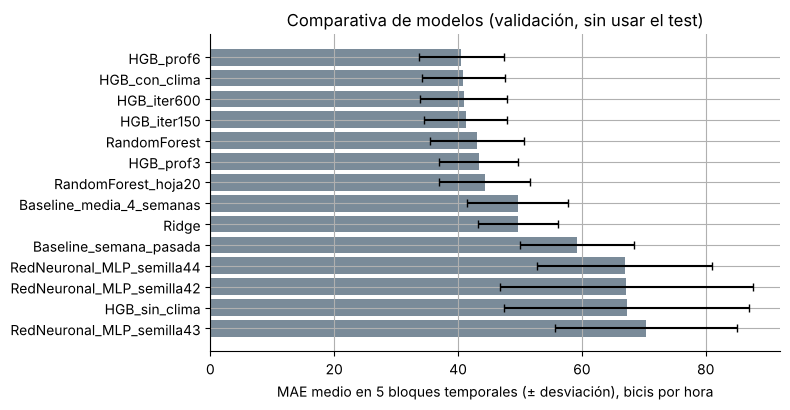

In [11]:
# Solo modelos legítimos: fuera los marcados «NO CANDIDATO»
legitimos = registro[~registro["notas"].fillna("").str.contains("NO CANDIDATO")].drop_duplicates(subset=["modelo", "hiperparametros"]).copy()
legitimos["val_sep_oct"] = [RESULTADOS[m]["val"] for m in legitimos["modelo"]]
ordenada = legitimos.sort_values("valor_cv")[["id", "responsable", "modelo", "valor_cv", "desv_cv", "val_sep_oct", "tiempo_s"]]
print(ordenada.round(2).to_string(index=False))

# Con series, el nivel de demanda cambia mucho de un bloque a otro (invierno frente a verano): la desviación es grande para todos.
# Por eso, además de media ± desviación, se compara CADA BLOQUE con el mejor (comparación emparejada).
mejor = legitimos.loc[legitimos["valor_cv"].idxmin(), "modelo"]
print("\nMejor por media:", mejor)
for m in ordenada["modelo"]:
    if m != mejor:
        dif = np.array(RESULTADOS[m]["bloques"]) - np.array(RESULTADOS[mejor]["bloques"])
        print(f"{m:<28} pierde con el mejor en {int((dif > 0).sum())} de 5 bloques · diferencia media {dif.mean():+.1f} bicis/hora")

fig, ax = plt.subplots(figsize=(8, 4.2))
t = ordenada.sort_values("valor_cv", ascending=False)
ax.barh(t["modelo"], t["valor_cv"], xerr=t["desv_cv"], color="#7a8b99", capsize=3)
ax.set_xlabel("MAE medio en 5 bloques temporales (± desviación), bicis por hora")
ax.set_title("Comparativa de modelos (validación, sin usar el test)")
plt.tight_layout(); plt.show()

In [12]:
# Elección con la validación (nunca con el test). Regla: si dos modelos van casi igual, el más simple y explicable.
CANDIDATO = "HGB_prof6"
assert CANDIDATO in set(legitimos["modelo"])
base = legitimos.set_index("modelo")
val_base = base.loc["Baseline_semana_pasada", "val_sep_oct"]
val_cand = base.loc[CANDIDATO, "val_sep_oct"]
objetivo = 0.75 * val_base
print(f"Candidato: {CANDIDATO} · MAE en validación sep–oct {val_cand:.1f} frente a {val_base:.1f} del baseline")
print(f"Mejora: {(1 - val_cand / val_base):.1%} · umbral de éxito: ≤ {objetivo:.1f} · ¿se cumple? {val_cand <= objetivo}")
print("Modelo sin clima:", round(float(base.loc["HGB_sin_clima", "val_sep_oct"]), 1), "· ¿cumple el umbral sin clima?", base.loc["HGB_sin_clima", "val_sep_oct"] <= objetivo)

Candidato: HGB_prof6 · MAE en validación sep–oct 42.2 frente a 69.5 del baseline
Mejora: 39.3% · umbral de éxito: ≤ 52.1 · ¿se cumple? True
Modelo sin clima: 63.9 · ¿cumple el umbral sin clima? False


## 6. Test, una sola vez

In [13]:
# TEST: UNA SOLA VEZ, después de elegir. Se calcula para el candidato y para el baseline y no se vuelve a tocar.
modelo_c, cols_c = MODELOS[CANDIDATO]
final = clone(modelo_c).fit(X_dev[cols_c], y_dev)                  # se entrena con todo lo anterior al test
pred_test = final.predict(X_test[cols_c])
res_test = informe_metricas(y_test, pred_test, hora_punta[m_test])
res_base_test = informe_metricas(y_test, X_test["lag_168"], hora_punta[m_test])
print("TEST (nov–dic 2012), mirado una vez:")
print(pd.DataFrame({"Candidato": res_test, "Baseline (semana pasada)": res_base_test}).T.round(3).to_string())
print(f"MAE en test {res_test['MAE']:.1f} frente a {val_cand:.1f} en validación (diferencia {res_test['MAE'] - val_cand:+.1f}) · mejora sobre el baseline: {1 - res_test['MAE'] / res_base_test['MAE']:.1%}")

TEST (nov–dic 2012), mirado una vez:
                             MAE   WAPE  MAE hora punta
Candidato                 44.009  0.233          85.531
Baseline (semana pasada)  75.368  0.399         140.562
MAE en test 44.0 frente a 42.2 en validación (diferencia +1.8) · mejora sobre el baseline: 41.6%


## 7. Guardar el modelo y los metadatos

In [14]:
import joblib

joblib.dump(final, "modelo_candidato.joblib")
metadatos = {
    "modelo": CANDIDATO,
    "tarea": "bicis alquiladas en cada hora de mañana, con lo conocido a las 23:00 de hoy",
    "entrenado": "2026-12-03",
    "semilla": SEMILLA,
    "datos_hash": DATOS_HASH,
    "metrica": METRICA,
    "valor_validacion": round(float(val_cand), 2),
    "valor_cv": [round(float(base.loc[CANDIDATO, "valor_cv"]), 2), round(float(base.loc[CANDIDATO, "desv_cv"]), 2)],
    "valor_test": round(float(res_test["MAE"]), 2),
    "variables": cols_c,
    "versiones": ENTORNO,
}
with open("metadatos.json", "w", encoding="utf8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)
print(open("metadatos.json").read())
recargado = joblib.load("modelo_candidato.joblib")
assert np.allclose(recargado.predict(X_test[cols_c]), pred_test)
print("✔ El modelo guardado da las mismas predicciones al cargarlo")

{
  "modelo": "HGB_prof6",
  "tarea": "bicis alquiladas en cada hora de mañana, con lo conocido a las 23:00 de hoy",
  "entrenado": "2026-12-03",
  "semilla": 42,
  "datos_hash": "95d6bcad",
  "metrica": "MAE (bicis/hora)",
  "valor_validacion": 42.19,
  "valor_cv": [
    40.56,
    6.84
  ],
  "valor_test": 44.01,
  "variables": [
    "hr",
    "weekday",
    "mnth",
    "holiday",
    "workingday",
    "lag_24",
    "lag_168",
    "media4sem",
    "nivel_7d",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed"
  ],
  "versiones": {
    "python": "3.13.18",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.9.1"
  }
}
✔ El modelo guardado da las mismas predicciones al cargarlo


## 8. Primera explicación (importancia por permutación)

media4sem     173.5
hr             11.8
hum            11.2
lag_168        10.3
lag_24          6.8
weathersit      6.6
workingday      6.1
temp            4.7


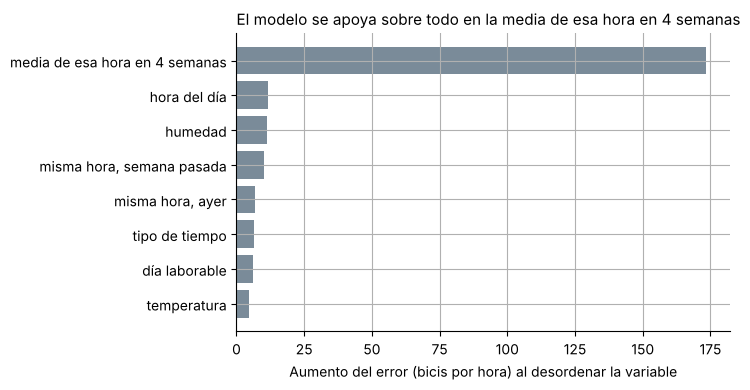

In [15]:
# Importancia por permutación en la VALIDACIÓN (no en el test), con el modelo entrenado solo con el entrenamiento
es_ent = X_dev.index < FIN_ENTRENAMIENTO
modelo_val = clone(modelo_c).fit(X_dev[es_ent][cols_c], y_dev[es_ent])
res = permutation_importance(modelo_val, X_dev[~es_ent][cols_c], y_dev[~es_ent], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=SEMILLA)
importancias = pd.Series(res.importances_mean, index=cols_c).sort_values(ascending=False)
print(importancias.head(8).round(1).to_string())

ETIQUETA = {"media4sem": "media de esa hora en 4 semanas", "lag_168": "misma hora, semana pasada", "lag_24": "misma hora, ayer", "nivel_7d": "nivel medio de 7 días",
            "hr": "hora del día", "weekday": "día de la semana", "mnth": "mes", "workingday": "día laborable", "holiday": "festivo",
            "weathersit": "tipo de tiempo", "temp": "temperatura", "atemp": "sensación térmica", "hum": "humedad", "windspeed": "viento"}
top = importancias.head(8)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh([ETIQUETA[v] for v in top.index], top.values, color="#7a8b99")
ax.set_xlabel("Aumento del error (bicis por hora) al desordenar la variable")
ax.set_title(f"El modelo se apoya sobre todo en la {ETIQUETA[importancias.index[0]]}", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig("explicacion_modelo.png", dpi=150)
plt.show()

## 9. Extra: ¿por qué gana?

In [16]:
# Extra: ¿por qué gana el candidato? Hipótesis: porque la demanda depende de la hora Y del tipo de día a la vez (cruces que una regresión lineal no ve).
modelo_lineal = clone(MODELOS["Ridge"][0]).fit(X_dev[es_ent][COLS_TODAS], y_dev[es_ent])
Xv, yv = X_dev[~es_ent], y_dev[~es_ent]
p_c, p_l = modelo_val.predict(Xv[cols_c]), modelo_lineal.predict(Xv[COLS_TODAS])
franjas = {"Laborable, hora punta": (Xv["workingday"] == 1) & Xv["hr"].isin([7, 8, 9, 17, 18, 19]),
           "Laborable, resto": (Xv["workingday"] == 1) & ~Xv["hr"].isin([7, 8, 9, 17, 18, 19]),
           "Fin de semana y festivos": Xv["workingday"] == 0}
filas = []
for nombre, mk in franjas.items():
    mk = mk.to_numpy()
    filas.append({"Franja": nombre, "Horas": int(mk.sum()), "MAE lineal": mae(yv.to_numpy()[mk], p_l[mk]), "MAE candidato": mae(yv.to_numpy()[mk], p_c[mk])})
franjas_df = pd.DataFrame(filas).round(1)
print(franjas_df.to_string(index=False))

                  Franja  Horas  MAE lineal  MAE candidato
   Laborable, hora punta    246        90.4           82.2
        Laborable, resto    738        34.3           28.9
Fin de semana y festivos    480        65.3           42.2


## 10. Cifras para la justificación

In [17]:
cifras = {
    "filas_registro": int(len(registro)), "por_responsable": registro["responsable"].value_counts().to_dict(),
    "datos_hash": DATOS_HASH, "candidato": CANDIDATO, "mejor_media": mejor,
    "tabla": [{"modelo": f["modelo"], "responsable": f["responsable"], "valor_cv": float(f["valor_cv"]), "desv_cv": float(f["desv_cv"]),
               "val": float(f["val_sep_oct"]), "tiempo_s": float(f["tiempo_s"]), "bloques": [round(v, 2) for v in RESULTADOS[f["modelo"]]["bloques"]]}
              for _, f in legitimos.sort_values("valor_cv").iterrows()],
    "no_candidatos": {n: {"valor_cv": float(registro.loc[registro["modelo"] == n, "valor_cv"].iloc[0]), "desv_cv": float(registro.loc[registro["modelo"] == n, "desv_cv"].iloc[0])}
                      for n in ("HGB_ConFuga", "HGB_KFold_barajado", "HGB_clima_con_error")},
    "val_clima_error": round(float(RESULTADOS["HGB_clima_con_error"]["val"]), 1),
    "val_base": round(float(val_base), 1), "val_cand": round(float(val_cand), 1), "objetivo": round(float(objetivo), 1),
    "val_punta_cand": round(float(RESULTADOS[CANDIDATO]["punta_val"]), 1), "val_punta_base": round(float(RESULTADOS["Baseline_semana_pasada"]["punta_val"]), 1),
    "test": {k: round(v, 3) for k, v in res_test.items()}, "test_base": {k: round(v, 3) for k, v in res_base_test.items()},
    "importancias": {k: round(float(v), 1) for k, v in importancias.head(8).items()},
    "franjas": franjas_df.to_dict("records"),
    "kb_joblib": round(os.path.getsize("modelo_candidato.joblib") / 1024),
    "versiones": ENTORNO,
}
print(json.dumps(cifras, ensure_ascii=False))

{"filas_registro": 18, "por_responsable": {"Persona C": 6, "Marta": 4, "Persona B": 4, "Persona D": 4}, "datos_hash": "95d6bcad", "candidato": "HGB_prof6", "mejor_media": "HGB_prof6", "tabla": [{"modelo": "HGB_prof6", "responsable": "Persona C", "valor_cv": 40.5557, "desv_cv": 6.845, "val": 42.19416634298254, "tiempo_s": 3.09, "bloques": [30.29, 48.7, 38.26, 43.33, 42.19]}, {"modelo": "HGB_con_clima", "responsable": "Marta", "valor_cv": 40.8496, "desv_cv": 6.7353, "val": 42.67105078837646, "tiempo_s": 3.37, "bloques": [30.55, 48.37, 38.58, 44.07, 42.67]}, {"modelo": "HGB_iter600", "responsable": "Persona C", "valor_cv": 40.9254, "desv_cv": 7.0334, "val": 42.28818292242401, "tiempo_s": 6.7, "bloques": [30.3, 49.14, 38.7, 44.2, 42.29]}, {"modelo": "HGB_iter150", "responsable": "Persona C", "valor_cv": 41.2243, "desv_cv": 6.7055, "val": 44.18297419943924, "tiempo_s": 2.01, "bloques": [30.77, 48.24, 38.95, 43.97, 44.18]}, {"modelo": "RandomForest", "responsable": "Persona D", "valor_cv": 4